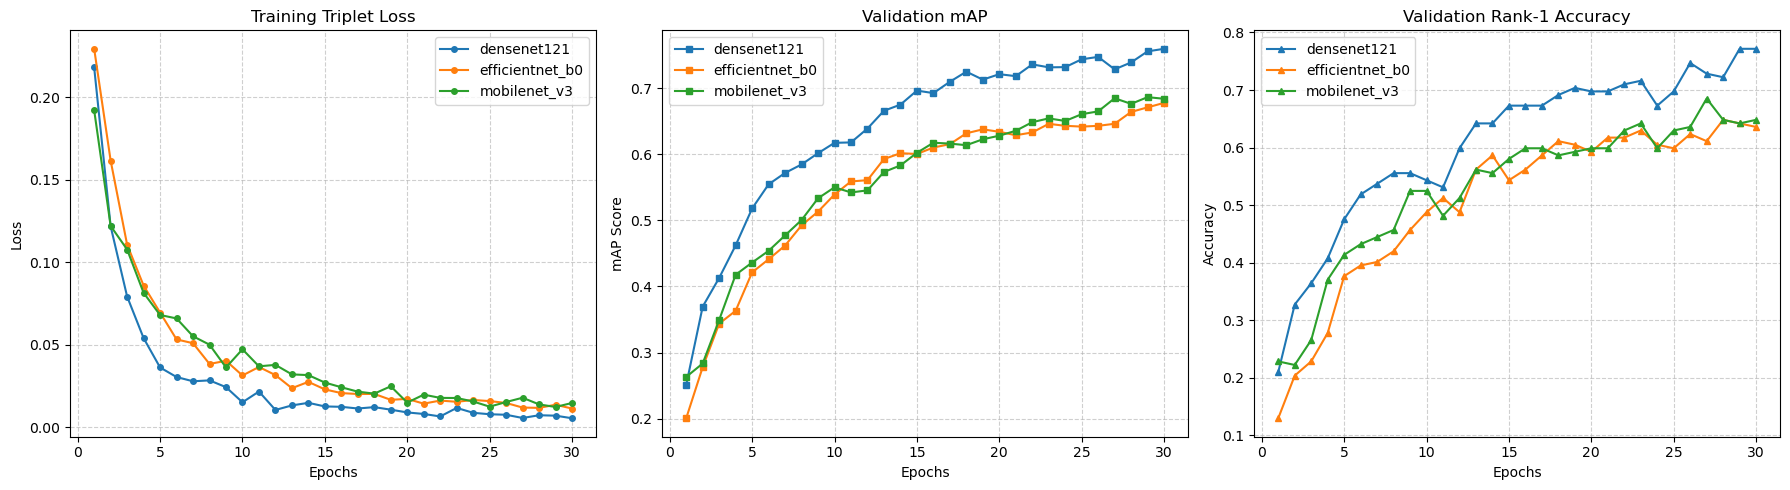

In [1]:
import os
import joblib
import matplotlib.pyplot as plt

# Define the models and their log file paths
models = ['densenet121', 'efficientnet_b0', 'mobilenet_v3']
histories = {}

# Load the joblib files
log_dir = "../outputs/logs/"
for model in models:
    file_path = os.path.join(log_dir, f"history_{model}.joblib")
    if os.path.exists(file_path):
        histories[model] = joblib.load(file_path)
    else:
        print(f"Warning: Log file for {model} not found at {file_path}")

# Plotting setup
if histories:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    epochs = range(1, len(next(iter(histories.values()))['train_loss']) + 1)
    
    # 1. Plot Training Loss
    for model, hist in histories.items():
        axes[0].plot(epochs, hist['train_loss'], label=model, marker='o', markersize=4)
    axes[0].set_title('Training Triplet Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Plot Validation mAP
    for model, hist in histories.items():
        axes[1].plot(epochs, hist['val_mAP'], label=model, marker='s', markersize=4)
    axes[1].set_title('Validation mAP')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('mAP Score')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    # 3. Plot Rank-1 Accuracy
    for model, hist in histories.items():
        axes[2].plot(epochs, hist['val_rank1'], label=model, marker='^', markersize=4)
    axes[2].set_title('Validation Rank-1 Accuracy')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('Accuracy')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("No history data available to plot yet. Run the training scripts first!")